Dataset Shape: (569, 30)

BASELINE MODEL
Architecture: (32, 16)
Learning Rate: 0.001
L2 Alpha: 0.0001
Early Stopping: False
Training Accuracy: 1.0
Test Accuracy: 0.956140350877193
Iterations: 295
---------------------------------------------


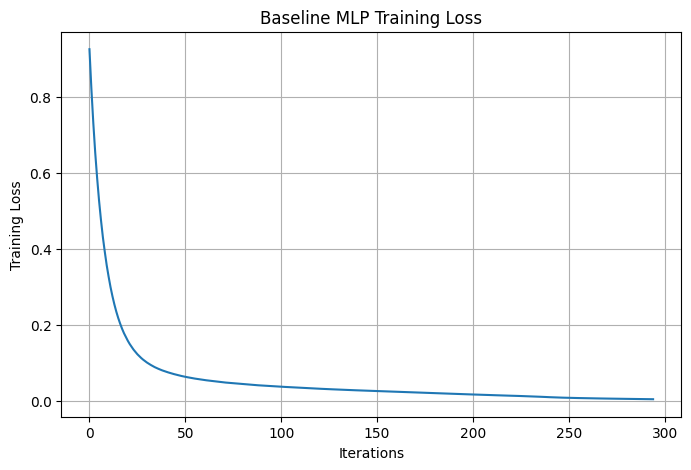


LEARNING RATE COMPARISON
Architecture: (32, 16)
Learning Rate: 0.0001
L2 Alpha: 0.0001
Early Stopping: False
Training Accuracy: 0.989010989010989
Test Accuracy: 0.9824561403508771
Iterations: 500
---------------------------------------------
Architecture: (32, 16)
Learning Rate: 0.001
L2 Alpha: 0.0001
Early Stopping: False
Training Accuracy: 1.0
Test Accuracy: 0.956140350877193
Iterations: 295
---------------------------------------------
Architecture: (32, 16)
Learning Rate: 0.1
L2 Alpha: 0.0001
Early Stopping: False
Training Accuracy: 0.9978021978021978
Test Accuracy: 0.9385964912280702
Iterations: 42
---------------------------------------------

ARCHITECTURE COMPARISON
Architecture: (16,)
Learning Rate: 0.001
L2 Alpha: 0.0001
Early Stopping: False
Training Accuracy: 0.9912087912087912
Test Accuracy: 0.9649122807017544
Iterations: 367
---------------------------------------------
Architecture: (32, 16)
Learning Rate: 0.001
L2 Alpha: 0.0001
Early Stopping: False
Training Accuracy: 1

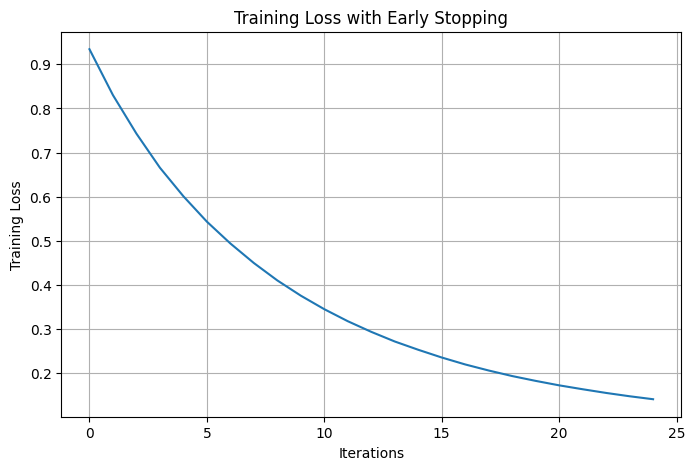

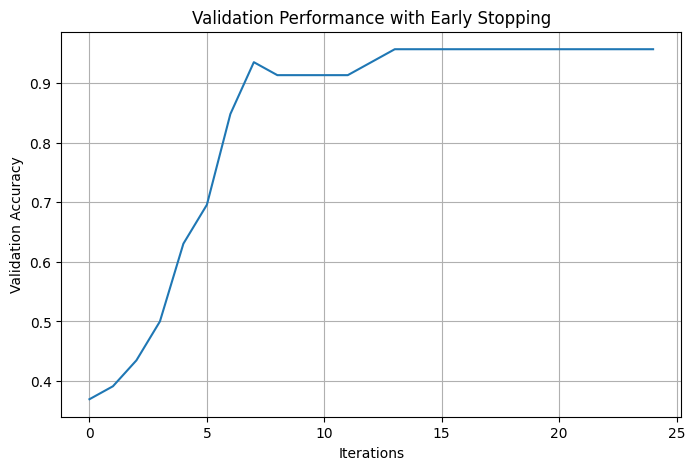


LEARNING RATE RESULTS
   Learning Rate  Training Accuracy  Test Accuracy
0         0.0001           0.989011       0.982456
1         0.0010           1.000000       0.956140
2         0.1000           0.997802       0.938596

ARCHITECTURE RESULTS
   Architecture  Training Accuracy  Test Accuracy
0         (16,)           0.991209       0.964912
1      (32, 16)           1.000000       0.956140
2  (64, 32, 16)           1.000000       0.964912

FINAL COMPARISON
          Experiment  Training Accuracy  Test Accuracy
0           Baseline           1.000000       0.956140
1  L2 Regularisation           1.000000       0.956140
2     Early Stopping           0.949451       0.921053


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")

# 1. Load Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)

# 2. Split Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Standardize Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Function to Train and Evaluate MLP
def evaluate_model(hidden_layers=(32, 16), lr=0.001,
                   alpha=0.0001, early=False):

    model = MLPClassifier(
        hidden_layer_sizes=hidden_layers,
        learning_rate_init=lr,
        alpha=alpha,
        early_stopping=early,
        validation_fraction=0.1,
        max_iter=500,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print("Architecture:", hidden_layers)
    print("Learning Rate:", lr)
    print("L2 Alpha:", alpha)
    print("Early Stopping:", early)
    print("Training Accuracy:", train_acc)
    print("Test Accuracy:", test_acc)
    print("Iterations:", model.n_iter_)
    print("-" * 45)

    return model, train_acc, test_acc


# 4. Train Baseline MLP Classifier
print("\nBASELINE MODEL")

baseline, train_acc, test_acc = evaluate_model(
    hidden_layers=(32, 16),
    lr=0.001
)

# 5. Plot Baseline Training Loss
plt.figure(figsize=(8, 5))
plt.plot(baseline.loss_curve_)
plt.xlabel("Iterations")
plt.ylabel("Training Loss")
plt.title("Baseline MLP Training Loss")
plt.grid()
plt.show()


# 6. Experiment with Different Learning Rates
learning_rates = [0.0001, 0.001, 0.1]
lr_results = []

print("\nLEARNING RATE COMPARISON")

for lr in learning_rates:
    model, tr, te = evaluate_model(lr=lr)
    lr_results.append([lr, tr, te])


# 7. Compare Different Network Architectures
architectures = [(16,), (32, 16), (64, 32, 16)]
architecture_results = []

print("\nARCHITECTURE COMPARISON")

for arch in architectures:
    model, tr, te = evaluate_model(hidden_layers=arch)
    architecture_results.append([str(arch), tr, te])


# 8. Apply L2 Regularisation
print("\nL2 REGULARISATION")

regularized, tr, te = evaluate_model(
    hidden_layers=(32, 16),
    lr=0.001,
    alpha=0.01
)


# 9. Apply Early Stopping
print("\nEARLY STOPPING")

early_model, tr, te = evaluate_model(
    hidden_layers=(32, 16),
    lr=0.001,
    early=True
)


# 10. Plot Training Loss with Early Stopping
plt.figure(figsize=(8, 5))
plt.plot(early_model.loss_curve_)
plt.xlabel("Iterations")
plt.ylabel("Training Loss")
plt.title("Training Loss with Early Stopping")
plt.grid()
plt.show()


# 11. Plot Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(early_model.validation_scores_)
plt.xlabel("Iterations")
plt.ylabel("Validation Accuracy")
plt.title("Validation Performance with Early Stopping")
plt.grid()
plt.show()


# 12. Display Learning Rate Results
lr_df = pd.DataFrame(
    lr_results,
    columns=["Learning Rate", "Training Accuracy", "Test Accuracy"]
)

print("\nLEARNING RATE RESULTS")
print(lr_df)


# 13. Display Architecture Results
arch_df = pd.DataFrame(
    architecture_results,
    columns=["Architecture", "Training Accuracy", "Test Accuracy"]
)

print("\nARCHITECTURE RESULTS")
print(arch_df)


# 14. Final Comparison
final_results = pd.DataFrame([
    ["Baseline", train_acc, test_acc],
    ["L2 Regularisation", regularized.score(X_train, y_train),
     regularized.score(X_test, y_test)],
    ["Early Stopping", early_model.score(X_train, y_train),
     early_model.score(X_test, y_test)]
], columns=["Experiment", "Training Accuracy", "Test Accuracy"])

print("\nFINAL COMPARISON")
print(final_results)
